# Motifs from contribution scores

A model's contribution scores show which bases it relied on. The short
stretches of high contribution, or seqlets, hold the sites of the factors it
has learned about. TF-MoDISco gathers seqlets that look alike into patterns.
This guide finds the same motifs a different way: it calls seqlets and runs
motif discovery on their letters.
[`contribution_motifs()`][universalmotif.contribution_motifs] does every step
in one call. It is experimental for now, so its options and results may
change in later releases.

We use the chromBPNet model of ATAC-seq in K562 cells from the
[motifs and deep learning](deep-learning.ipynb) guide, and compare what we
find with the model's own [TF-MoDISco results](tfmodisco.ipynb).

In [1]:
import pathlib
import tarfile
import time
import urllib.request

import numpy as np
import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(40);

## Downloading the data

We need the regions the model was interpreted on, its contribution scores
and the sequence of chromosome 1. To compare with, we also need the model's
TF-MoDISco results and the JASPAR 2024 vertebrate motifs. The contribution
scores are a bigWig track of 2.1 GB. Reading thousands of regions from
ENCODE's server would take hours, so the track is downloaded once:

In [2]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url, name=None):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / (name or url.rsplit("/", 1)[-1])
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

ENCODE = "https://www.encodeproject.org/files"
regions_path = fetch(f"{ENCODE}/ENCFF834JBL/@@download/ENCFF834JBL.bed.gz")
scores_path = fetch(f"{ENCODE}/ENCFF407GCO/@@download/ENCFF407GCO.bigWig")
modisco_tar = fetch(f"{ENCODE}/ENCFF009WUL/@@download/ENCFF009WUL.tar.gz")
chr1_path = fetch("https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr1.fa.gz")
jaspar_path = fetch("https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt")

modisco_path = CACHE / "counts" / "tfmodisco.raw_output.counts.ENCSR868FGK.hd5"
if not modisco_path.exists():
    with tarfile.open(modisco_tar) as tar:
        tar.extract(f"counts/{modisco_path.name}", CACHE, filter="data")

## The regions

The model was interpreted on 1 kb windows around accessible regions. We take
those on chromosome 1 and keep the middle 500 bases of each, where most of
the contribution is, with [`resize_ranges()`][universalmotif.resize_ranges].
[`drop_overlaps()`][universalmotif.drop_overlaps] then drops windows that
overlap one kept before, so no base is counted twice:

In [3]:
regions = um.read_bed(regions_path).filter(pl.col("chrom") == "chr1").sort("start")
windows = um.drop_overlaps(um.resize_ranges(regions, 500))
print(regions.height, "regions,", windows.height, "windows kept")

31165 regions, 21292 windows kept


[`signal_values()`][universalmotif.signal_values] reads the score of every
base of each window from the track.
[`extract_ranges()`][universalmotif.extract_ranges] reads the windows'
sequences from chromosome 1:

In [4]:
chr1 = um.read_fasta(chr1_path)
seqs = [s.upper() for s in um.extract_ranges(chr1, windows).values()]
scores = np.stack([um.signal_values(scores_path, c, s, e) for c, s, e in windows.iter_rows()])
scores.shape

(21292, 500)

## Finding the motifs

`contribution_motifs()` takes the scores and their sequences. By default it
searches the positive seqlets, those of bases that raised the prediction. It
works in these steps:

1. It calls seqlets with [`call_seqlets()`][universalmotif.call_seqlets],
   in two passes. The second pass calls them again with the first pass's
   seqlets set to 0, which finds weaker sites beside strong ones.
2. It searches their letters with
   [`motif_finder()`][universalmotif.motif_finder], against windows away
   from any seqlet.
3. It rebuilds each motif from its sites in the seqlets with
   [`refine_motifs()`][universalmotif.refine_motifs].
4. It keeps the motifs that reach enough new seqlets with
   [`select_motifs()`][universalmotif.select_motifs], leaving out repeats.
5. It searches again in the seqlets that no motif reaches yet.
6. It looks for composite motifs, two parts with a spacer, with
   [`gapped_motif_finder()`][universalmotif.gapped_motif_finder].
7. It drops motifs whose matches carry no more contribution than those of
   shuffled copies of themselves, such as runs of GCs.
8. It finds where the model used each motif, as described below.

In [5]:
t = time.time()
found = um.contribution_motifs(scores, seqs, seed=1, nthreads=2)
print(f"{found!r} in {time.time() - t:.1f} s")
found.motifs.select("name", "pattern", "source", "consensus", "seqlets")

ContributionMotifs(54 motifs in 29 patterns from 74,018 seqlets) in 99.3 s


name,pattern,source,consensus,seqlets
str,str,str,str,i64
"""pos_1""","""pos_p2""","""seqlets""","""CCCCGCCCCY""",5975
"""pos_2""","""pos_p7""","""seqlets""","""CCASYAGRKGGCR""",1379
"""pos_113""","""pos_p28""","""seqlets""","""AGAGYRARACYCYGTCTCAAAAAAAAAAAA""",71
"""pos_4""","""pos_p8""","""seqlets""","""TGACTCAK""",1590
"""pos_r1""","""pos_p3""","""seqlets""","""AGATAAAAR""",5908
"""pos_13""","""pos_p10""","""seqlets""","""ACTTCCTG""",1633
"""pos_10""","""pos_p2""","""seqlets""","""CMCTBCCYCCWSC""",669
"""pos_15""","""pos_p2""","""seqlets""","""GCCACRCCC""",1796
"""pos_91""","""pos_p25""","""seqlets""","""ACTACANYTCCCAGNNNNC""",223


Each motif comes as a PPM in the `motif` column and as a CWM in the `cwm`
column. The CWM is the mean contribution of each letter at the motif's sites
in the seqlets. `seqlets` counts the seqlets given to the motif. Each seqlet
goes to the one motif whose CWM matches its scores best, as TF-MoDISco gives
each seqlet to one pattern. Motifs are chosen by the seqlets their sequence
matches reach, so a motif can be given fewer seqlets here than it added when
it was chosen. Names starting with `pos_r` come from the second
search, and those starting with `pos_g` are composites.

## Patterns

Some motifs are spellings of one site that each reach seqlets the others
miss. `patterns` gathers them, much as TF-MoDISco gathers seqlets. Taking the
motifs in order of the seqlets their sequence matches reach, each joins the
first pattern whose first motif's CWM is at least 0.8 like its own by cosine.
Each pattern is shown by its member given the most seqlets:

In [6]:
found.patterns.select("pattern", "representative", "consensus", "seqlets", "members")

pattern,representative,consensus,seqlets,members
str,str,str,i64,list[str]
"""pos_p1""","""pos_r18""","""AARGAARCCG""",13288,"[""pos_r18"", ""pos_17"", … ""pos_r32""]"
"""pos_p2""","""pos_1""","""CCCCGCCCCY""",11318,"[""pos_1"", ""pos_43"", … ""pos_10""]"
"""pos_p3""","""pos_r1""","""AGATAAAAR""",8571,"[""pos_r1"", ""pos_r57"", … ""pos_115""]"
"""pos_p4""","""pos_r47""","""CCGCNRAGC""",7369,"[""pos_r47"", ""pos_r80""]"
"""pos_p5""","""pos_r44""","""ASWCCGSCTR""",4855,"[""pos_r44"", ""pos_r42""]"
"""pos_p6""","""pos_r52""","""AKAACGAAA""",4326,"[""pos_r52""]"
"""pos_p7""","""pos_r123""","""CCACANGGKG""",3568,"[""pos_r123"", ""pos_2"", ""pos_48""]"
"""pos_p8""","""pos_4""","""TGACTCAK""",3498,"[""pos_4"", ""pos_95"", ""pos_53""]"
"""pos_p9""","""pos_r41""","""AARCVGCC""",2382,"[""pos_r41""]"


Here are the CWMs of the first eight patterns:

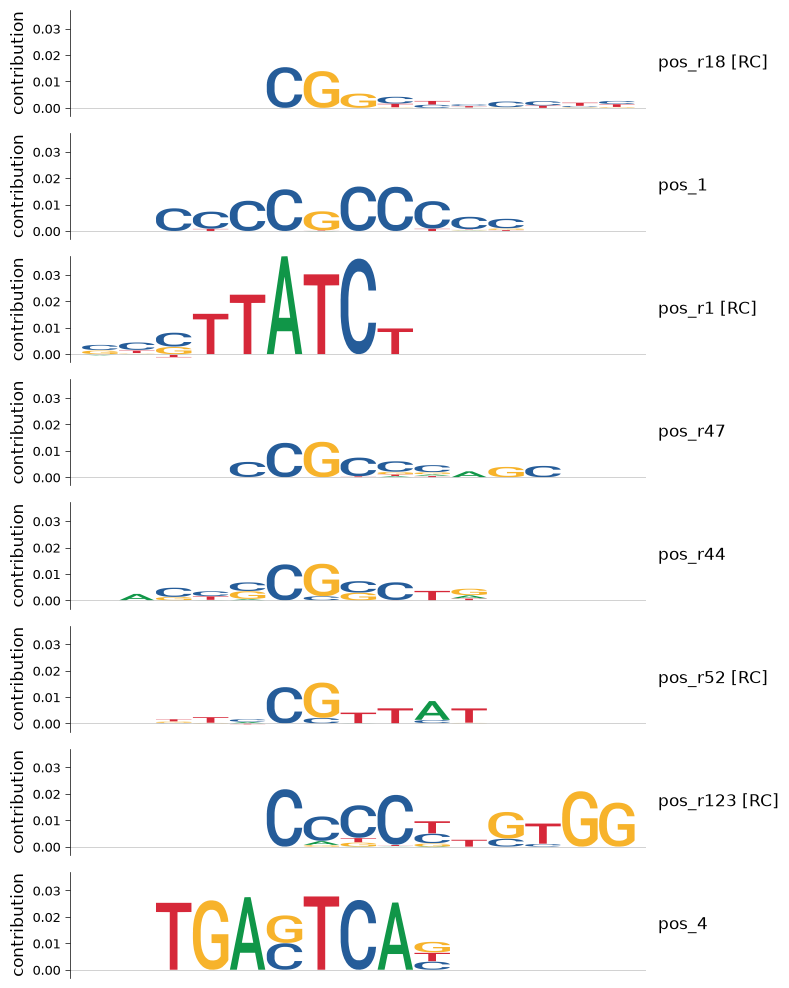

In [7]:
fig = um.view_motifs(found.patterns["cwm"].to_list()[:8], names_pos="right", show_positions=False,
                     figsize=(8, 10))

## Naming the patterns

[`name_motifs()`][universalmotif.name_motifs] names each pattern by the
JASPAR motif it resembles most. To compare with TF-MoDISco, we also find each
pattern's closest TF-MoDISco pattern by CWM cosine. Those patterns were found
in all 270,000 of the model's regions, not just the 21,000 or so windows of
chromosome 1 used here:

In [8]:
jaspar = um.read_meme(jaspar_path)
pats = found.patterns
names = um.name_motifs(pats["motif"].to_list(), jaspar, top=1, nthreads=2)

modisco = [m.replace(name=f"pattern_{m.name.rsplit('_', 1)[1]}")
           for m in um.read_modisco(modisco_path) if m.name.startswith("pos")]
cmp = um.compare_motifs(pats["cwm"].to_list() + modisco, compare_to=list(range(pats.height)), qvalue=1,
                        nthreads=2)
closest = (cmp.filter(pl.col("target_i") >= pats.height).sort("score", descending=True)
           .group_by("subject_i", maintain_order=True).first())
(
    pats.with_row_index("i").select("i", "pattern", "consensus", "seqlets")
    .join(names.select(i=pl.col("motif_i").cast(pl.UInt32), jaspar="altname"), on="i", how="left")
    .join(closest.select(i="subject_i", tfmodisco="target", cosine=pl.col("score").round(2)), on="i", how="left")
    .drop("i")
)

pattern,consensus,seqlets,jaspar,tfmodisco,cosine
str,str,i64,str,str,f64
"""pos_p1""","""AARGAARCCG""",13288,null,"""pattern_30""",0.85
"""pos_p2""","""CCCCGCCCCY""",11318,"""SP1""","""pattern_2""",0.96
"""pos_p3""","""AGATAAAAR""",8571,null,"""pattern_0""",0.98
"""pos_p4""","""CCGCNRAGC""",7369,null,"""pattern_43""",0.79
"""pos_p5""","""ASWCCGSCTR""",4855,null,"""pattern_30""",0.79
"""pos_p6""","""AKAACGAAA""",4326,null,"""pattern_10""",0.86
"""pos_p7""","""CCACANGGKG""",3568,null,"""pattern_1""",0.85
"""pos_p8""","""TGACTCAK""",3498,"""FOSL2""","""pattern_3""",0.95
"""pos_p9""","""AARCVGCC""",2382,null,"""pattern_2""",0.78


Most patterns match a TF-MoDISco pattern closely, and their JASPAR names are
the factors of the [TF-MoDISco results](tfmodisco.ipynb) guide. Among them
are the GC box of SP and KLF, GATA, AP-1, ETS, Kaiso, ATF4, NFI, NF-Y, NRF1,
CTCF, STAT5 and THAP11. (GATA's pattern goes unnamed at this q-value, but its
closest TF-MoDISco pattern is TF-MoDISco's GATA.) Several of the largest
patterns, such as `AARGAARCCG` and `AKAACGAAA`, come from the second search
and have no JASPAR name. TF-MoDISco finds patterns like them too, so the
model has learned them, though which factors they belong to is unclear.

[`plot_modisco()`][universalmotif.plot_modisco] draws the patterns as the
same report it draws for TF-MoDISco results. Each pattern gets a row with its
number of seqlets, its logos and its closest database motifs. With `html`, it
also writes the report as an HTML page, whose columns sort and whose rows
open to show each pattern's CWMs. A button in each row turns its logos to
their reverse complements.
[`ContributionMotifs.report()`][universalmotif.ContributionMotifs.report]
writes just the page:

```python
fig = um.plot_modisco(found, database=jaspar, patterns=8, html="k562-motifs.html")
```

## How well it works

To see how well this works, `contribution_motifs()` was run on 25 of
ENCODE's models: BPNet models of 16 single factors, chromBPNet models of
accessibility in K562, HepG2 and GM12878 cells (this one among them), and
ProCapNet models of transcription initiation in six cell lines. No set of
motifs is known to be complete for any of them, so rather than score one
method against another, each motif was checked for evidence of its own:

- conservation at its sites, or more ChIP-seq peaks of the factor it is
  named after than expected;
- a change in the model's prediction when it is planted in shuffled
  sequences, against copies of it with its columns shuffled.

The table gives the distinct motifs per model with either kind of evidence,
and those with none:

| Run | BPNet | chromBPNet | ProCapNet counts | ProCapNet profile |
| --- | ---: | ---: | ---: | ---: |
| `contribution_motifs()` | 28.4 / 3.8 | 50.7 / 13.7 | 60.2 / 8.2 | 41.7 / 17.8 |
| TF-MoDISco, same regions | 12.4 / 1.4 | 26.7 / 1.0 | 21.8 / 2.2 | 26.3 / 12.0 |
| TF-MoDISco, ENCODE's results | 10.9 / 0.4 | 46.7 / 2.7 | 28.2 / 2.3 | 24.8 / 13.7 |

TF-MoDISco was run with at most 50,000 seqlets of each sign, its cap here,
while `contribution_motifs()` searched every seqlet it called.
`contribution_motifs()` finds more motifs with evidence on every kind of
model, though on chromBPNet, with several times as many seqlets as the cap,
part of that may come from seeing more of the data. The gain is clearest on BPNet, where the second seqlet pass finds the
sites of cofactors beside the factor's own. It also finds more motifs
without evidence. These are an upper bound on noise, since motifs of factors
without ChIP-seq data, or whose sites are not conserved, land there too.
(Note that on chromBPNet and ProCapNet much of what it adds is backed by the
model's response alone.) The [Benchmarks](../benchmarks.md) page gives the
details, with the evidence split by kind.


## A model of transcription initiation

Models of transcription initiation rely on shorter elements than models of
accessibility. ProCapNet predicts PRO-cap signal, which marks where
transcription starts. Its K562 model relies on the initiator, a CA or TA at
the start site, and on the TATA box about 30 bases upstream. Both are only a
few letters long. ENCODE provides the model's scores for 30,534 peaks, with
the TF-MoDISco results of its counts and profile heads
([ENCSR740IPL](https://www.encodeproject.org/annotations/ENCSR740IPL/)). The
scores come as NumPy arrays with the letters last:

```python
hyp = np.load("profile/ENCSR261KBX.input.hyp.contrib.scores.npy").transpose(0, 2, 1)
onehot = np.load("profile/ENCSR261KBX.input.seqs.npy").transpose(0, 2, 1)
observed = (hyp * onehot).sum(axis=1)
found = um.contribution_motifs(observed, um.from_one_hot(onehot), hypothetical=hyp, seed=1, nthreads=2)
```

Of all the heads checked, ProCapNet's profile heads are where
`contribution_motifs()` struggles most. Their scores rest on elements of two
to four letters, such as the initiator and the TATA box. Elements this short
do not stand out by their letters alone. A CA is found almost anywhere, and
a motif of four letters cannot reach the P-value of 1e-4 that the motifs are
chosen by. The initiator is found, when it is found at all, within longer
motifs whose CWMs put most of their weight on the CA, and spellings that differ in their
weaker flanks can still form separate patterns. Profile heads also gave the
most motifs without any evidence, about 18 of the 60 per model (and 12 of 38
for TF-MoDISco). For these heads it is worth trying seqlets called in a
single pass with `call_seqlets(observed, sequences, min_len=2,
threshold=0.05)`, which suit their spikier scores, and checking the short
elements against TF-MoDISco's patterns.


## Where the model used each motif

A scan of the sequence finds every site that looks like a motif.
[`scan_contributions()`][universalmotif.scan_contributions] instead matches
a CWM against the contribution scores, so it finds the sites the model used.
A window is a hit when two measures reach the motif's thresholds:

- its similarity, the cosine between its scores and the CWM;
- its importance, the sum of its absolute scores as a fraction of the CWM's.

`contribution_motifs()` sets these thresholds from each motif's own sites in
the seqlets, so that 95% of them would pass each one. Its `hits` table holds
the hits of every motif in all the windows:

In [9]:
print(found.hits.height, "hits in", len(seqs), "windows")
found.thresholds.head(8)

1380946 hits in 21292 windows


motif,min_similarity,min_importance
str,f64,f64
"""pos_1""",0.801935,0.433034
"""pos_2""",0.748391,0.2967
"""pos_113""",0.7,0.5
"""pos_4""",0.859943,0.238277
"""pos_r1""",0.865174,0.261753
"""pos_13""",0.793645,0.473732
"""pos_10""",0.632344,0.591915
"""pos_15""",0.740751,0.459034


Every motif is matched on its own, so similar motifs can each have a hit at
one site. To draw a single window, we match again with the same thresholds,
keeping only the best hit where hits of different motifs overlap. We pick the
window with the most different motifs among the first 3,000:

In [10]:
hits = um.scan_contributions(found.cwms, scores[:3000], sequences=seqs[:3000], thresholds=found.thresholds,
                             no_overlaps_across_motifs=True, nthreads=2)
row = int(hits.group_by("sequence_i").agg(pl.col("motif").n_unique().alias("n"))
          .sort("n", "sequence_i", descending=[True, False])["sequence_i"][0])
here = hits.filter(pl.col("sequence_i") == row)
here.select("motif", "start", "end", "strand", "match", "similarity", "importance")

motif,start,end,strand,match,similarity,importance
str,i64,i64,str,str,f64,f64
"""pos_1""",474,484,"""+""","""CCCCACCCTA""",0.820522,0.480562
"""pos_r1""",337,346,"""+""","""AGATAGTGA""",0.910705,0.319626
"""pos_17""",319,327,"""+""","""CCGGAAGG""",0.982466,2.298368
"""pos_39""",250,260,"""+""","""ACGCCAGCGT""",0.815831,0.495914
"""pos_r55""",279,288,"""-""","""GCTTCTGTC""",0.556918,0.646742
"""pos_r55""",288,297,"""+""","""GATAACGTC""",0.881207,2.360891
"""pos_77""",327,337,"""-""","""CTGCTCTCTC""",0.624998,0.474995
"""pos_r32""",226,236,"""-""","""CCCCTGCCGG""",0.938687,0.901715
"""pos_r27""",199,208,"""+""","""GCGCTCGCA""",0.692391,0.990833


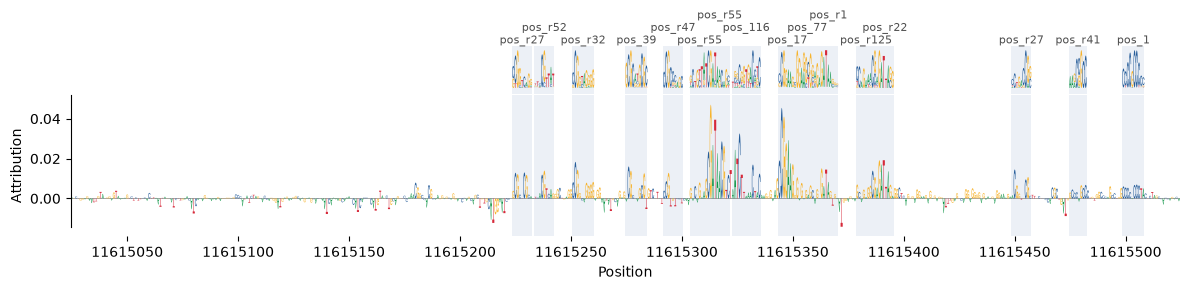

In [11]:
c, s, e = windows.row(row)
ax = um.view_attributions(scores[row], seqs[row], start=s, hits=here, motifs=found.cwms, figsize=(12, 3))

## Choosing the settings

The defaults aim at the patterns a model has learned. They keep a motif when
it adds at least 0.25% of the seqlets (0.2% in the second search), its CWM
differs from those kept, and its matches carry more contribution than those
of shuffled copies of it.
For a short list of motifs that reach as many seqlets as possible, such as
for scanning new sequences, keep motifs that add at least 1% and drop the
CWM comparison:

In [12]:
short = um.contribution_motifs(scores, seqs, seed=1, nthreads=2, min_gain=0.01, max_similarity=None)
short.motifs.select("name", "consensus", "seqlets", "gain", "cumulative")

name,consensus,seqlets,gain,cumulative
str,str,i64,f64,f64
"""pos_1""","""CCCCKCCCCC""",5598,0.047394,0.145694
"""pos_2""","""CCASYAGRKGGCR""",2307,0.043273,0.188968
"""pos_113""","""AGAGNRARACYCYGTCTCAAAAAAAAAAAA""",83,0.028358,0.217326
"""pos_4""","""TGACTCAB""",1976,0.025088,0.242414
"""pos_13""","""ACTTCCTS""",2211,0.019333,0.285241
"""pos_3""","""RNAGATAAGRR""",1696,0.01728,0.302521
"""pos_10""","""CMCTBCCYCCWSC""",1675,0.016618,0.319139
"""pos_51""","""YTYWTTATCTCH""",1555,0.015564,0.350496
"""pos_8""","""TGATAAGRN""",2268,0.014578,0.365073


Here `gain` is the share of seqlets each motif adds, in the order chosen, and
`cumulative` the share reached so far. Both count the seqlets reached by the
motifs' sequence matches, by which they were chosen. Rare motifs now drop out,
while similar motifs stay because each catches sites the others miss.

Other options change one step each:

| Option | What it does |
| --- | --- |
| `hypothetical` | Adds a search on seqlets rewritten in the letters the model prefers, which finds degenerate sites such as NFI more reliably |
| `seqlet_passes=1` | Calls seqlets once, which is quicker and gives fewer motifs without other evidence, but misses weaker sites beside strong ones |
| `null_scores` | The model's scores for shuffled sequences, the strictest null for calling seqlets; with them a second pass adds little |
| `contribution_test=None` | Keeps the motifs the contribution test would drop |
| `later_min_gain` | The share of seqlets a motif from the second search must add, by default four fifths of `min_gain` |
| `stability=4` | Keeps only motifs found again in most searches of half the seqlets, at the cost of rare motifs |
| `sign="both"` | Also searches the negative seqlets, which are only reliable with `null_scores` |
| `seqlets` | Seqlets to use instead of calling them, such as TF-MoDISco's |
| `max_seqlets` | Searches a random sample of at most this many seqlets of each sign, which bounds the time on large sets of regions at the cost of rare motifs |
| `rounds=1`, `gapped=False`, `hits=False` | Leave out the second search, the composites or the matching, for a quicker call |

The bigWig track holds only the scores of the bases present, so we can't
show `hypothetical` here. [`read_contributions()`][universalmotif.read_contributions]
reads hypothetical scores from the files of chromBPNet and of ENCODE. The
[experiments on a model](model-experiments.ipynb) guide shows how to compute
scores, and the scores of shuffled sequences, with a model of your own.

Scores from a model's profile head are spikier than those of its counts
head, with a few strong bases between weak ones. Seqlets called with
`min_len=2` and `threshold=0.05` suit them better. Called this way they come
from a single pass, which also gives fewer motifs without other evidence on
profile heads:

```python
seqlets = um.call_seqlets(scores, seqs, min_len=2, threshold=0.05)
found = um.contribution_motifs(scores, seqs, seqlets=seqlets)
```

## Step by step

Each step of `contribution_motifs()` is a function of its own, for more
control over any of them. [`call_seqlets()`][universalmotif.call_seqlets]
calls a stretch a seqlet when its total contribution is unlikely under a
null built from the scores themselves. The same must hold for every stretch
inside it, so a seqlet holds no run of unremarkable bases. The large scores
of strong sites stretch the top of that null, so a second pass, with the
first pass's seqlets set to 0, finds weaker sites the first missed. We call
them in two passes, as `contribution_motifs()` does:

In [13]:
seqlets = um.call_seqlets(scores, seqs, passes=2, seed=1, nthreads=2)
seqlets.group_by("sign").agg(pl.len(), pl.col("end").sub(pl.col("start")).median().alias("median width"))

sign,len,median width
str,u32,f64
"""-""",242789,12.0
"""+""",71261,14.0


Negative seqlets come out far more numerous than positive ones, which says
more about the null than about the model. Their false discovery rate comes
from the scores shuffled within each window, a null too lenient for faint
negative scores, and the model's scores for shuffled sequences avoid this.

The search, refinement and selection are then ordinary calls, with the
seqlets as the sites the motifs should reach:

In [14]:
pos = seqlets.filter(pl.col("sign") == "+")
targets = [seqs[i][max(s - 3, 0):e + 3] for i, s, e in pos.select("sequence_i", "start", "end").iter_rows()]
plain = um.motif_finder(targets, nmotifs=20, seed=1, nthreads=2)
refined = um.refine_motifs(plain, seqs, sites=pos, min_overlap=5, nthreads=2)
chosen = um.select_motifs(refined, seqs, sites=pos, min_overlap=5, nthreads=2)
chosen.select("motif", "rank", "targets", "gain", "kept").head(10)

motif,rank,targets,gain,kept
str,u32,u64,f64,bool
"""motif_1""",1,4888,0.068593,true
"""motif_30""",2,3893,0.053929,true
"""motif_3""",3,3424,0.045607,true
"""motif_28""",4,4347,0.03744,true
"""motif_2""",5,2877,0.034942,true
"""motif_4""",6,2234,0.028318,true
"""motif_6""",7,2327,0.027827,true
"""motif_32""",8,2061,0.018257,true
"""motif_7""",9,2903,0.016727,true


Here `motif_finder()` compares the seqlets with three shuffles of themselves,
its default background. `contribution_motifs()` uses windows from the regions
away from any seqlet instead. That keeps sequence common to all accessible
regions, such as GC-rich stretches, from looking enriched.

## Saving disk space

Hypothetical scores take four numbers per base, so for a genome-wide set of
regions they can fill far more disk than the sequences themselves. They are
only needed to idealize the seqlets, and
[`idealize_sequences()`][universalmotif.idealize_sequences] looks at one
position at a time. Each batch of regions can therefore be idealized as the
model scores it, and its hypothetical scores dropped. Only the observed
scores, one number per base, and the idealized letters are kept:

```python
observed, letters, ideal = [], [], []
for seqs, hyp in batches:  # each batch's sequences and their hypothetical scores
    onehot = um.one_hot(seqs)
    observed.append((hyp * onehot).sum(axis=1).astype(np.float16))
    letters += seqs
    ideal += um.idealize_sequences(seqs, hyp)
found = um.contribution_motifs(np.concatenate(observed), letters, idealized=ideal)
```

When even the observed scores are too many to keep, seqlets can be called
batch by batch, as long as every batch has the same null scores. The model's
scores for shuffled sequences make the best null, though the first batch's
scores shuffled also work. Each batch is called with `fdr=None` to keep every
candidate, and the null scores are called once the same way.
[`seqlet_fdr()`][universalmotif.seqlet_fdr] then applies one false discovery
rate to them all, which gives exactly the seqlets of a single call:

```python
null = np.random.default_rng(1).permuted(first_batch, axis=1)
candidates, positions = [], 0
for start, obs, seqs in batches:  # the first row of each batch, and its scores and sequences
    found = um.call_seqlets(obs, seqs, null_scores=null, fdr=None)
    candidates.append(found.with_columns(pl.col("sequence_i") + start))
    positions += obs.size
null_seqlets = um.call_seqlets(null, null_scores=null, fdr=None)
seqlets = um.seqlet_fdr(pl.concat(candidates), null_seqlets, positions=positions, null_positions=null.size)
```

Keeping only the scores within 30 bases of a seqlet saves more space, but
the motifs found from them are not quite the same. The second seqlet pass
and the contribution test both look at scores further away. On the windows
of this guide, 30% of the positions were kept, and 52 motifs were found
against 54, many of the rarer ones different. Without the rest of the
scores, `contribution_motifs()` also cannot find hits outside those windows. A
second pass of the model, scanned with
[`scan_contributions()`][universalmotif.scan_contributions] and the motifs'
CWMs, finds them instead.